# Optimizing Fraud Detection in Card Transactions
Anil Bammidi · DSC680 · Milestone 3

**Run:** Put the original `creditcard.csv` beside this notebook, install the packages listed below and run all cells in order. The file is available from [Machine Learning Group–ULB on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). The run writes figures and performance summaries to `fraud_results/`.

**Questions:** Can a Random Forest rank fraud better than logistic regression on later transactions? Can training-only SMOTE improve the fraction of fraud caught at the same validation alert target, and what workload results on the later holdout?

The dataset represents two days of European card transactions in September 2013. The experiment measures retrospective discrimination and review workload.

In [1]:
import hashlib
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             fbeta_score, precision_recall_curve, precision_score, recall_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 42
directory = Path('fraud_results')
directory.mkdir(exist_ok=True)
versions = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print(versions)

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


{'python': '3.8.20', 'numpy': '1.24.4', 'pandas': '2.0.3', 'sklearn': '1.3.2', 'matplotlib': '3.7.3'}


## Data dictionary and preparation

| Field | Meaning and use |
| --- | --- |
| Time | Seconds since the first recorded transaction. Used only for chronological splitting. Its origin has no verified clock time. |
| Amount | Recorded nonnegative transaction amount. Model uses `log1p(Amount)` to compress the right tail while preserving zero. |
| V1–V28 | Numeric PCA features supplied by the publisher. Original variables are undisclosed. All 28 components enter the model. |
| Class | Outcome. 1 = fraud, 0 = genuine. Excluded from predictors. |

One public source, with no joins. Check schema, numeric values, labels, missingness and nonnegative time/amount. Drop exact full-row duplicates, keeping the first recorded copy. Without transaction IDs, identical rows could represent separate events. Retain high amounts and report all row removals. Split at 18 and 24 elapsed hours. Train and fit the scaler on the earliest block, choose operating thresholds on the middle block, and evaluate on the later holdout.

In [2]:
data_path = Path('data/creditcard.csv')
if not data_path.exists():
    raise FileNotFoundError('Place the source creditcard.csv in the data/ folder.')
digest = hashlib.sha256()
with data_path.open('rb') as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b''):
        digest.update(chunk)
checksum = digest.hexdigest()

components = [f'V{i}' for i in range(1, 29)]
raw = pd.read_csv(data_path)
expected = ['Time', *components, 'Amount', 'Class']
assert list(raw.columns) == expected
missing = int(raw.isna().sum().sum())
assert missing == 0 and np.isfinite(raw.to_numpy()).all()
assert set(raw.Class.unique()) == {0, 1} and raw[['Time', 'Amount']].ge(0).all().all()

clean = raw.drop_duplicates().sort_values('Time', kind='stable')
windows = {
    'Train': clean.Time.lt(18 * 3600),
    'Validation': clean.Time.ge(18 * 3600) & clean.Time.lt(24 * 3600),
    'Holdout': clean.Time.ge(24 * 3600),
}
features = clean[components].assign(LogAmount=np.log1p(clean.Amount))
labels = {name: clean.loc[mask, 'Class'].to_numpy() for name, mask in windows.items()}
assert sum(map(len, labels.values())) == len(clean)
assert all(set(y) == {0, 1} for y in labels.values())

scaler = StandardScaler().fit(features.loc[windows['Train']])
inputs = {name: scaler.transform(features.loc[mask]) for name, mask in windows.items()}
audit = dict(raw_rows=len(raw), raw_fraud=int(raw.Class.sum()), missing=missing,
             duplicate_rows=len(raw)-len(clean), fraud_duplicates=int(raw.Class.sum()-clean.Class.sum()),
             retained_rows=len(clean), retained_fraud=int(clean.Class.sum()), sha256=checksum)
partition = {name: dict(rows=len(y), fraud=int(y.sum())) for name, y in labels.items()}
print(audit)
print(pd.DataFrame(partition).T.to_string())

{'raw_rows': 284807, 'raw_fraud': 492, 'missing': 0, 'duplicate_rows': 1081, 'fraud_duplicates': 19, 'retained_rows': 283726, 'retained_fraud': 473, 'sha256': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89'}
              rows  fraud
Train        93924    217
Validation   50312     55
Holdout     139490    201


## Methods and validation

The always-genuine baseline demonstrates why accuracy is misleading. Logistic regression provides a simpler linear ranking benchmark. Random Forest captures nonlinear interactions among the PCA inputs (Breiman, 2001). Two otherwise identical forests isolate the effect of adding SMOTE (Chawla et al., 2002). Gradient boosting and cost-weighted models are alternatives for future comparison. Sequence models require entity history unavailable here.

The notebook implements standard minority-neighbor interpolation using five minority neighbors and a fixed seed. Scaling is fitted on the training block and makes the distance calculation less sensitive to differing scales. SMOTE raises training fraud to 5% of the genuine count. This fixed ratio limits synthetic dominance and is an experimental setting. Model settings are fixed in advance for a comparable run.

For each trained classifier, choose the lowest score cutoff whose validation alert count stays at or below 0.5% of transactions. The 0.5% figure illustrates review constraints and is not based on observed staffing or costs. Equal-score ties move together. Freeze the cutoffs for the holdout. Average precision (AP) evaluates ranking over thresholds. Precision, recall, F2 and confusion counts evaluate the frozen operating point. A single ordered validation block fits this two-day design. Multi-period rolling validation remains future work.

In [3]:
def smote_training_data(X, y, ratio=0.05):
    minority = X[y == 1]
    synthetic_count = int(np.ceil(ratio * (y == 0).sum())) - len(minority)
    if synthetic_count <= 0:
        return X, y
    neighbors = NearestNeighbors(n_neighbors=5).fit(minority).kneighbors(return_distance=False)
    rng = np.random.default_rng(SEED)
    source = rng.integers(len(minority), size=synthetic_count)
    partner = neighbors[source, rng.integers(5, size=synthetic_count)]
    weight = rng.random((synthetic_count, 1))
    synthetic = minority[source] + weight * (minority[partner] - minority[source])
    return np.vstack([X, synthetic]), np.r_[y, np.ones(synthetic_count, dtype=y.dtype)]

def budget_cutoff(scores, fraction=0.005):
    values, counts = np.unique(scores, return_counts=True)
    allowed = np.cumsum(counts[::-1]) <= int(fraction * len(scores))
    if not allowed.any():
        return float(np.nextafter(values[-1], np.inf))
    return float(values[::-1][allowed][-1])

def evaluate(y, scores, cutoff):
    predictions = scores >= cutoff
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    return dict(AP=average_precision_score(y, scores),
                accuracy=accuracy_score(y, predictions),
                precision=precision_score(y, predictions, zero_division=0),
                recall=recall_score(y, predictions),
                F2=fbeta_score(y, predictions, beta=2, zero_division=0),
                alert_rate=float(predictions.mean()), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

forest_settings = dict(n_estimators=40, max_depth=12, min_samples_leaf=2,
                       max_features='sqrt', random_state=SEED, n_jobs=4)
models = {
    'Always genuine': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Random Forest': RandomForestClassifier(**forest_settings),
    'Random Forest + SMOTE': RandomForestClassifier(**forest_settings),
}
train_X, train_y = inputs['Train'], labels['Train']
synthetic_X, synthetic_y = smote_training_data(train_X, train_y)
audit['synthetic_train_rows'] = len(synthetic_y) - len(train_y)

scores_by_split = {split: {} for split in ('Validation', 'Holdout')}
results = {split: {} for split in scores_by_split}
cutoffs = {}
for name, model in models.items():
    model.fit(*( (synthetic_X, synthetic_y) if name.endswith('SMOTE') else (train_X, train_y) ))
    for split in scores_by_split:
        scores_by_split[split][name] = model.predict_proba(inputs[split])[:, 1]
    cutoff = budget_cutoff(scores_by_split['Validation'][name])
    cutoffs[name] = cutoff
    for split in results:
        results[split][name] = evaluate(labels[split], scores_by_split[split][name], cutoff)

for split, metrics in results.items():
    print(split)
    print(pd.DataFrame(metrics).T.round(4).to_string())
print('Frozen score thresholds:', cutoffs)
print('Synthetic training rows:', audit['synthetic_train_rows'])

Validation
                           AP  accuracy  precision  recall      F2  alert_rate       TN     FP    FN    TP
Always genuine         0.0011    0.9989     0.0000  0.0000  0.0000       0.000  50257.0    0.0  55.0   0.0
Logistic regression    0.5390    0.9955     0.1633  0.7455  0.4352       0.005  50047.0  210.0  14.0  41.0
Random Forest          0.6979    0.9956     0.1673  0.7636  0.4459       0.005  50048.0  209.0  13.0  42.0
Random Forest + SMOTE  0.6998    0.9956     0.1673  0.7636  0.4459       0.005  50048.0  209.0  13.0  42.0
Holdout
                           AP  accuracy  precision  recall      F2  alert_rate        TN      FP     FN     TP
Always genuine         0.0014    0.9986     0.0000  0.0000  0.0000      0.0000  139289.0     0.0  201.0    0.0
Logistic regression    0.5587    0.9919     0.1233  0.7562  0.3731      0.0088  138208.0  1081.0   49.0  152.0
Random Forest          0.7476    0.9655     0.0359  0.8856  0.1543      0.0356  134504.0  4785.0   23.0  178.0
Ra

## Visual results

The precision–recall baseline equals fraud prevalence (Saito & Rehmsmeier, 2015). The confusion matrix is for the forest with the higher validation AP. The validation sensitivity plot illustrates workload before transferring the score cutoff to the holdout.

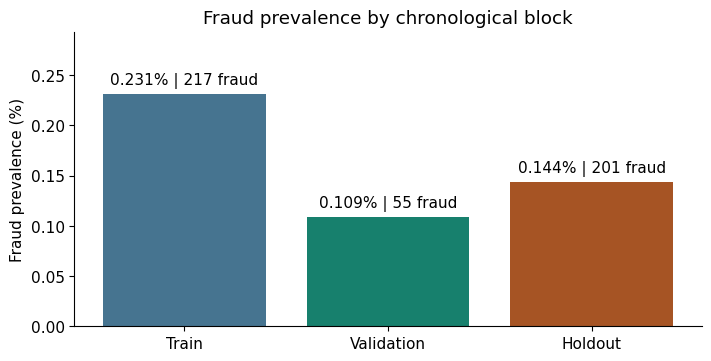

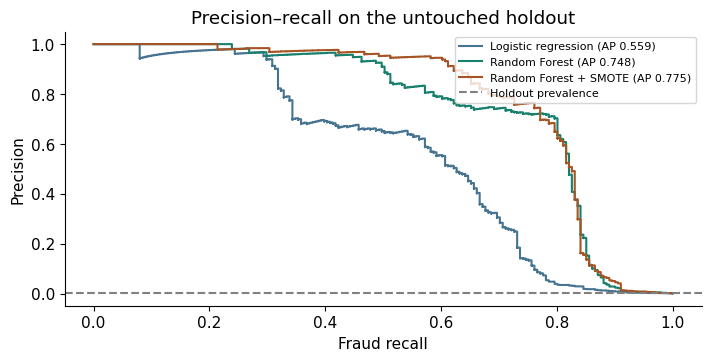

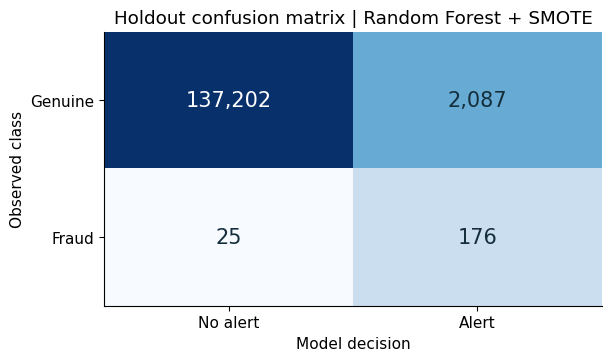

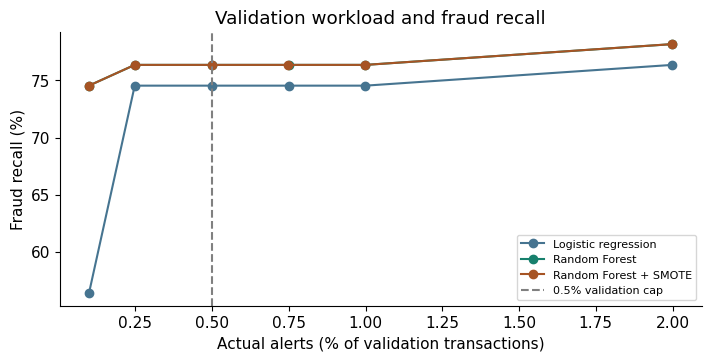

In [4]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
colors = {'Logistic regression':'#467490','Random Forest':'#17806d','Random Forest + SMOTE':'#a65424'}
forest = max(('Random Forest', 'Random Forest + SMOTE'), key=lambda n: results['Validation'][n]['AP'])
paths = []

def save_figure(fig, name):
    path = directory / f'{name}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    paths.append(path)
    if 'get_ipython' in globals():
        plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
rates = [100 * y.mean() for y in labels.values()]
bars = ax.bar(labels.keys(), rates, color=['#467490', '#17806d', '#a65424'])
ax.bar_label(bars, labels=[f'{rate:.3f}% | {int(y.sum())} fraud' for rate,y in zip(rates,labels.values())], padding=4)
ax.set(ylabel='Fraud prevalence (%)', title='Fraud prevalence by chronological block', ylim=(0, max(rates)*1.27))
save_figure(fig, '01_prevalence')

fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
for name, color in colors.items():
    precision, recall, _ = precision_recall_curve(labels['Holdout'], scores_by_split['Holdout'][name])
    ax.step(recall, precision, where='post', color=color, label=f'{name} (AP {results["Holdout"][name]["AP"]:.3f})')
ax.axhline(labels['Holdout'].mean(), color='gray', linestyle='--', label='Holdout prevalence')
ax.set(xlabel='Fraud recall', ylabel='Precision', title='Precision–recall on the untouched holdout')
ax.legend(fontsize=8, loc='upper right')
save_figure(fig, '02_precision_recall')

fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
m = results['Holdout'][forest]
matrix = np.array([[m['TN'],m['FP']],[m['FN'],m['TP']]])
ax.imshow(np.log1p(matrix), cmap='Blues', aspect='auto')
for (i,j), value in np.ndenumerate(matrix):
    ax.text(j,i,f'{value:,}',ha='center',va='center',color='white' if (i,j)==(0,0) else '#142e3c',fontsize=15)
ax.set(xticks=[0,1], yticks=[0,1], xticklabels=['No alert','Alert'], yticklabels=['Genuine','Fraud'],
       xlabel='Model decision', ylabel='Observed class', title=f'Holdout confusion matrix | {forest}')
save_figure(fig, '03_confusion')

fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
targets = [0.001,0.0025,0.005,0.0075,0.01,0.02]
for name, color in colors.items():
    y, scores = labels['Validation'], scores_by_split['Validation'][name]
    measurements = [evaluate(y,scores,budget_cutoff(scores,p)) for p in targets]
    ax.plot([m['alert_rate']*100 for m in measurements],[m['recall']*100 for m in measurements],
            marker='o',color=color,label=name)
ax.axvline(.5,color='gray',linestyle='--',label='0.5% validation cap')
ax.set(xlabel='Actual alerts (% of validation transactions)',ylabel='Fraud recall (%)',
       title='Validation workload and fraud recall')
ax.legend(fontsize=8, loc='lower right')
save_figure(fig, '04_workload')

summary = dict(versions=versions, audit=audit, partition=partition, cutoffs=cutoffs,
               results=results, figure_forest=forest)
(directory / 'summary.json').write_text(json.dumps(summary, indent=2))
capture = paths

## Interpretation

On the later holdout, plain Random Forest achieved AP 0.748, compared with 0.566 for logistic regression and 0.775 for SMOTE Random Forest. At the validation-derived cutoff, plain Random Forest caught 178 of 201 frauds and generated 4785 false alerts. The SMOTE forest caught 176 of 201 and generated 2087 false alerts. Both forests caught 42 of 55 validation frauds with 251 alerts. This does not support a recall benefit from SMOTE at the tested validation cap. The SMOTE forest attained the highest holdout AP, while logistic regression achieved the highest holdout F2 (0.311) at the frozen operating points. All learned models exceeded the 0.5% alert target on the holdout. Advance logistic regression and SMOTE Random Forest for shadow validation. Model scores are uncalibrated. The holdout measures one later period from the same source and cannot establish modern effectiveness, fairness, or economic savings.

## References
- Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32. https://doi.org/10.1023/A:1010933404324
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953
- Machine Learning Group–ULB. (n.d.). *Credit card fraud detection* [Data set]. Kaggle. https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Original notebook workflow reference: Kabure. (n.d.). *Credit card fraud prediction—RF, SMOTE* [Notebook]. Kaggle. https://www.kaggle.com/code/kabure/credit-card-fraud-prediction-rf-smote